# SIR: uncertainty in transmission and recovery rates

Part A: a homogeneous differential-equation model, **not a cellular automaton**.
Each run draws parameters once and keeps them fixed throughout integration.

$$\dot S=-\beta SI,\quad \dot I=\beta SI-\gamma I,\quad \dot R=\gamma I,\qquad S+I+R=1.$$

Select the `simulation/.venv/bin/python` kernel. Install dependencies with
`uv sync --extra notebook` from `simulation`, then run all cells in order.
All plots and summaries below are reproducible with a fixed seed.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import truncnorm
from IPython.display import display, Markdown

from simulation.core.SIR import SIR
from simulation.validation import sir_final_susceptible

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.2})

## Configuration

Start with 100 runs per scenario; use 500–2000 for more stable tails and deciles.
Time is measured in arbitrary consistent units; beta and gamma are rates per unit
time, not probabilities, so they may exceed 1.

`I_THRESHOLD` defines practical extinction: the first downward crossing of the
infectious fraction below this threshold. With the default initial condition,
I starts above the threshold. Unobserved crossings are **right-censored** at
`T_END`, not assigned a duration equal to `T_END`.

Durations and peaks are estimated on the common output grid (default spacing 0.5).
Refine `OUTPUT_DT` and increase `T_END` to check numerical and horizon sensitivity.

In [2]:
SEED = 2026
N_RUNS = 100
I0 = 0.01
BETA0 = 0.30
GAMMA0 = 0.10
T_END = 600.0
OUTPUT_DT = 0.5
I_THRESHOLD = 1e-5
OBSERVATION_TIMES = (20.0, 60.0, 120.0)

assert N_RUNS >= 2 and 0 < I_THRESHOLD < I0 < 1
assert T_END > 0 and OUTPUT_DT > 0
assert all(0 <= t <= T_END for t in OBSERVATION_TIMES)
POINTS = int(np.ceil(T_END / OUTPUT_DT)) + 1
INITIAL = (1 - I0, I0, 0.0)

## Parameter distributions

- **Fixed:** no parameter uncertainty.
- **Gaussian:** $X\sim\mathcal N(\mu,\sigma^2)\mid X>0$.
  `mu` and `sigma` describe the **parent Gaussian**. Truncation changes the actual
  mean and standard deviation; the tables report empirical values. Thus the retained
  perturbation is not exactly centered at zero. This matters most when sigma is
  large relative to mu. We do not clip negative draws to zero or take absolute values.
- **Uniform:** mean `mu`, standard deviation `sigma`, bounds
  $\mu\pm\sqrt{3}\sigma$; the lower bound must be positive.
- **Lognormal:** positive distribution parameterized by its arithmetic mean `mu`
  and standard deviation `sigma`.

Draws of beta and gamma are independent. A correlation model would be a separate
experiment. Initial infectious fraction remains fixed in this notebook.

In [3]:
def draw_rate(rng, spec, size):
    kind, mu, sigma = spec
    if mu <= 0 or sigma < 0:
        raise ValueError("Use a positive mean and a nonnegative standard deviation")
    if kind == "fixed" or sigma == 0:
        return np.full(size, mu)
    if kind == "gaussian":
        return truncnorm.rvs(-mu / sigma, np.inf, loc=mu, scale=sigma,
                            size=size, random_state=rng)
    if kind == "uniform":
        half_width = np.sqrt(3) * sigma
        if mu - half_width <= 0:
            raise ValueError("Uniform lower bound must be positive")
        return rng.uniform(mu - half_width, mu + half_width, size)
    if kind == "lognormal":
        log_variance = np.log1p((sigma / mu) ** 2)
        return rng.lognormal(np.log(mu) - log_variance / 2,
                             np.sqrt(log_variance), size)
    raise ValueError(f"Unknown distribution: {kind}")


def spec_text(spec):
    kind, mu, sigma = spec
    return f"{kind}: mu={mu:g}, sigma={sigma:g}"


def make_scenario(name, beta=None, gamma=None):
    return {"name": name,
            "beta": beta if beta is not None else ("fixed", BETA0, 0),
            "gamma": gamma if gamma is not None else ("fixed", GAMMA0, 0)}


beta_scenarios = [make_scenario("Fixed baseline")]
beta_scenarios += [make_scenario(f"beta mean {mu:g}", beta=("gaussian", mu, 0.02))
                   for mu in (0.15, 0.30, 0.45)]
beta_scenarios += [make_scenario(f"beta spread {sd:g}", beta=("gaussian", BETA0, sd))
                   for sd in (0.06, 0.12)]

gamma_scenarios = [make_scenario("Fixed baseline")]
gamma_scenarios += [make_scenario(f"gamma mean {mu:g}", gamma=("gaussian", mu, 0.01))
                    for mu in (0.05, 0.10, 0.20)]
gamma_scenarios += [make_scenario(f"gamma spread {sd:g}", gamma=("gaussian", GAMMA0, sd))
                    for sd in (0.03, 0.07)]

joint_scenarios = [make_scenario("Fixed baseline")]
joint_scenarios += [make_scenario(f"Both Gaussian: {label}",
                    beta=("gaussian", BETA0, bs), gamma=("gaussian", GAMMA0, gs))
                    for label, bs, gs in (("small", 0.02, 0.01),
                                           ("medium", 0.06, 0.03),
                                           ("large", 0.12, 0.07))]

family_scenarios = [make_scenario(f"Both {kind}",
                    beta=(kind, BETA0, 0.06), gamma=(kind, GAMMA0, 0.03))
                   for kind in ("gaussian", "uniform", "lognormal")]

## Ensemble computation

Every trajectory uses the existing `SIR.solve()` implementation. All runs use the
same output times, so I(t) and R(t)+I(t) can be compared directly.

Final size is **R(infinity)** computed from the analytical final-size equation by
bisection, using the existing `sir_final_susceptible` helper. Because initial R is
zero and gamma is positive, this also equals the total fraction ever infected.
It is kept separate from R(T_END). No history is extrapolated past T_END.

In [4]:
def run_scenario(config, rng):
    beta = draw_rate(rng, config["beta"], N_RUNS)
    gamma = draw_rate(rng, config["gamma"], N_RUNS)
    paths = np.empty((N_RUNS, 3, POINTS))
    duration = np.full(N_RUNS, np.nan)
    final_size = np.empty(N_RUNS)
    for j, (b, g) in enumerate(zip(beta, gamma)):
        solution = SIR(INITIAL, beta=b, gamma=g).solve(
            (0, T_END), points=POINTS, rtol=1e-7, atol=1e-10)
        times = solution.t
        paths[j] = solution.y
        infected = solution.y[1]
        crossings = np.flatnonzero((infected[:-1] > I_THRESHOLD)
                                  & (infected[1:] <= I_THRESHOLD))
        if crossings.size:
            k = crossings[0]
            weight = (infected[k] - I_THRESHOLD) / (infected[k] - infected[k + 1])
            duration[j] = times[k] + weight * (times[k + 1] - times[k])
        s_inf = sir_final_susceptible(INITIAL, beta=b, gamma=g)
        final_size[j] = 1 - s_inf
    assert np.max(np.abs(paths.sum(axis=1) - 1)) < 1e-7
    assert paths.min() > -1e-7
    return {"config": config, "times": times, "paths": paths,
            "beta": beta, "gamma": gamma, "duration": duration,
            "final_size": final_size, "peak_I": paths[:, 1].max(axis=1)}


def run_group(configs, seed):
    streams = np.random.SeedSequence(seed).spawn(len(configs))
    return [run_scenario(config, np.random.default_rng(stream))
            for config, stream in zip(configs, streams)]


def markdown_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(str, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def summarize(results):
    rows = []
    for result in results:
        duration = result["duration"]
        observed = duration[np.isfinite(duration)]
        final = result["final_size"]
        q10, q50, q90 = np.quantile(final, [0.1, 0.5, 0.9])
        rows.append([result["config"]["name"],
                     f'{result["beta"].mean():.3f} ± {result["beta"].std(ddof=1):.3f}',
                     f'{result["gamma"].mean():.3f} ± {result["gamma"].std(ddof=1):.3f}',
                     f"{final.mean():.3f} ± {final.std(ddof=1):.3f}",
                     f"{q10:.3f} / {q50:.3f} / {q90:.3f}",
                     f"{100 * (1 - len(observed) / N_RUNS):.1f}%",
                     f"{observed.mean():.1f}" if observed.size else "not observed"])
    markdown_table(["Scenario", "beta: sample mean ± SD", "gamma: sample mean ± SD",
                    "R(infinity): mean ± SD", "R(infinity): D1 / D5 / D9",
                    "Duration censored", "Mean duration, observed only"], rows)


def plot_group(results):
    fig, axes = plt.subplots(2, 3, figsize=(16, 8), layout="constrained")
    for result in results:
        name = result["config"]["name"]
        times, paths = result["times"], result["paths"]
        line, = axes[0, 0].plot(times, paths[:, 1].mean(axis=0), label=name)
        color = line.get_color()
        low, high = np.quantile(paths[:, 1], [0.1, 0.9], axis=0)
        axes[0, 0].fill_between(times, low, high, color=color, alpha=0.08)
        cumulative = paths[:, 1] + paths[:, 2]
        axes[0, 1].plot(times, cumulative.mean(axis=0), color=color)
        ordered = np.sort(result["final_size"])
        axes[0, 2].step(ordered, np.arange(1, N_RUNS + 1) / N_RUNS,
                        where="post", color=color)
        # These histograms show sample counts, including constant baselines.
        axes[1, 0].hist(result["beta"], bins=20, histtype="step", color=color)
        axes[1, 1].hist(result["gamma"], bins=20, histtype="step", color=color)
        observed = np.sort(result["duration"][np.isfinite(result["duration"])])
        # Divide by ALL runs: unresolved durations remain beyond the horizon.
        axes[1, 2].step(np.r_[0, observed, T_END],
                        np.r_[0, np.arange(1, len(observed) + 1) / N_RUNS,
                              len(observed) / N_RUNS], where="post", color=color)
    axes[0, 0].set(title="I(t): mean and 10–90% run band", xlabel="Time", ylabel="Fraction")
    axes[0, 1].set(title="Mean R(t) + I(t)", xlabel="Time", ylabel="Fraction")
    axes[0, 2].set(title="Final-size empirical CDF", xlabel="R(infinity)", ylabel="Fraction of runs")
    axes[1, 0].set(title="Sampled beta", xlabel="Transmission rate", ylabel="Count", xlim=(0, None))
    axes[1, 1].set(title="Sampled gamma", xlabel="Recovery rate", ylabel="Count", xlim=(0, None))
    axes[1, 2].set(title="Observed extinction CDF (all runs)", xlabel="Duration", ylabel="Fraction of runs")
    axes[0, 0].legend(fontsize=8)
    plt.show()

## 1. Gaussian beta: change the mean and spread

Gamma stays at 0.10. Compare the three parent means at sigma=0.02, then compare
spread at mean=0.30. Larger beta generally promotes a larger and earlier epidemic,
but greater spread need not have a monotonic effect on ensemble averages.
Shaded bands describe run variability, **not confidence intervals for the mean**.

| Scenario | beta: sample mean ± SD | gamma: sample mean ± SD | R(infinity): mean ± SD | R(infinity): D1 / D5 / D9 | Duration censored | Mean duration, observed only |
| --- | --- | --- | --- | --- | --- | --- |
| Fixed baseline | 0.300 ± 0.000 | 0.100 ± 0.000 | 0.941 ± 0.000 | 0.941 / 0.941 / 0.941 | 0.0% | 161.3 |
| beta mean 0.15 | 0.152 ± 0.019 | 0.100 ± 0.000 | 0.583 ± 0.126 | 0.419 / 0.609 / 0.738 | 0.0% | 334.8 |
| beta mean 0.3 | 0.298 ± 0.019 | 0.100 ± 0.000 | 0.938 ± 0.014 | 0.920 / 0.940 / 0.953 | 0.0% | 162.5 |
| beta mean 0.45 | 0.449 ± 0.022 | 0.100 ± 0.000 | 0.988 ± 0.003 | 0.985 / 0.988 / 0.991 | 0.0% | 135.7 |
| beta spread 0.06 | 0.314 ± 0.054 | 0.100 ± 0.000 | 0.938 ± 0.043 | 0.876 / 0.951 / 0.978 | 0.0% | 161.9 |
| beta spread 0.12 | 0.311 ± 0.112 | 0.100 ± 0.000 | 0.880 ± 0.186 | 0.713 / 0.949 / 0.986 | 1.0% | 176.1 |

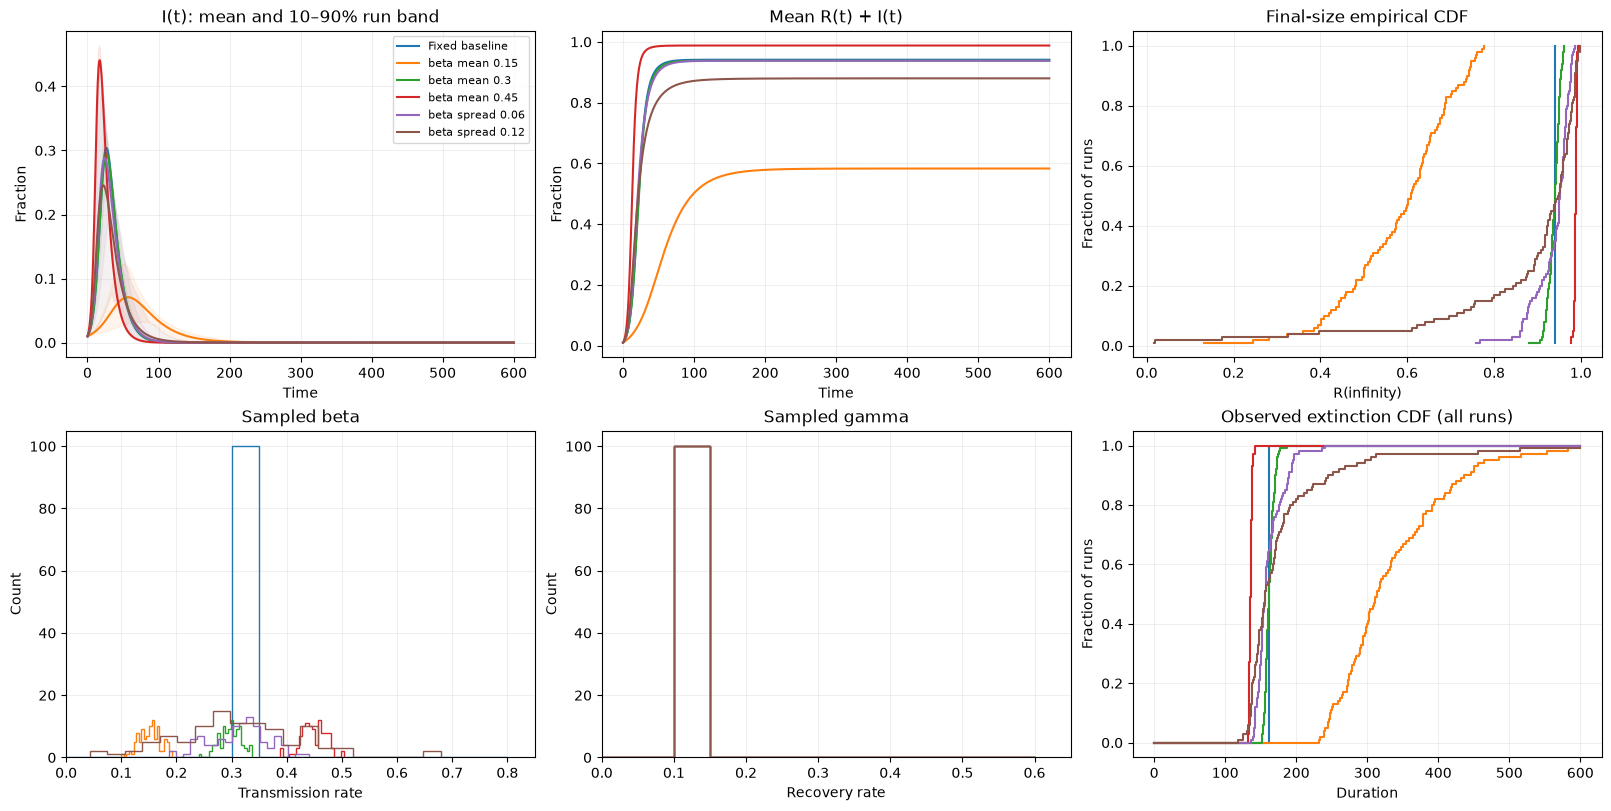

In [5]:
beta_results = run_group(beta_scenarios, SEED)
summarize(beta_results)
plot_group(beta_results)

## 2. Gaussian gamma: change the mean and spread

Beta stays at 0.30. Larger gamma means a shorter mean infectious period 1/gamma.
Wide Gaussian recovery uncertainty can produce rates very close to zero and long
right tails in epidemic duration. Check the censored percentage before interpreting
the mean duration of observed runs; that mean excludes unresolved long epidemics.

| Scenario | beta: sample mean ± SD | gamma: sample mean ± SD | R(infinity): mean ± SD | R(infinity): D1 / D5 / D9 | Duration censored | Mean duration, observed only |
| --- | --- | --- | --- | --- | --- | --- |
| Fixed baseline | 0.300 ± 0.000 | 0.100 ± 0.000 | 0.941 ± 0.000 | 0.941 / 0.941 / 0.941 | 0.0% | 161.3 |
| gamma mean 0.05 | 0.300 ± 0.000 | 0.051 ± 0.009 | 0.996 ± 0.004 | 0.992 / 0.997 / 0.999 | 0.0% | 255.7 |
| gamma mean 0.1 | 0.300 ± 0.000 | 0.098 ± 0.010 | 0.943 ± 0.020 | 0.915 / 0.945 / 0.965 | 0.0% | 163.6 |
| gamma mean 0.2 | 0.300 ± 0.000 | 0.202 ± 0.011 | 0.584 ± 0.051 | 0.522 / 0.590 / 0.643 | 0.0% | 162.5 |
| gamma spread 0.03 | 0.300 ± 0.000 | 0.103 ± 0.027 | 0.922 ± 0.056 | 0.840 / 0.934 / 0.987 | 0.0% | 168.5 |
| gamma spread 0.07 | 0.300 ± 0.000 | 0.106 ± 0.057 | 0.881 ± 0.145 | 0.660 / 0.940 / 1.000 | 5.0% | 190.5 |

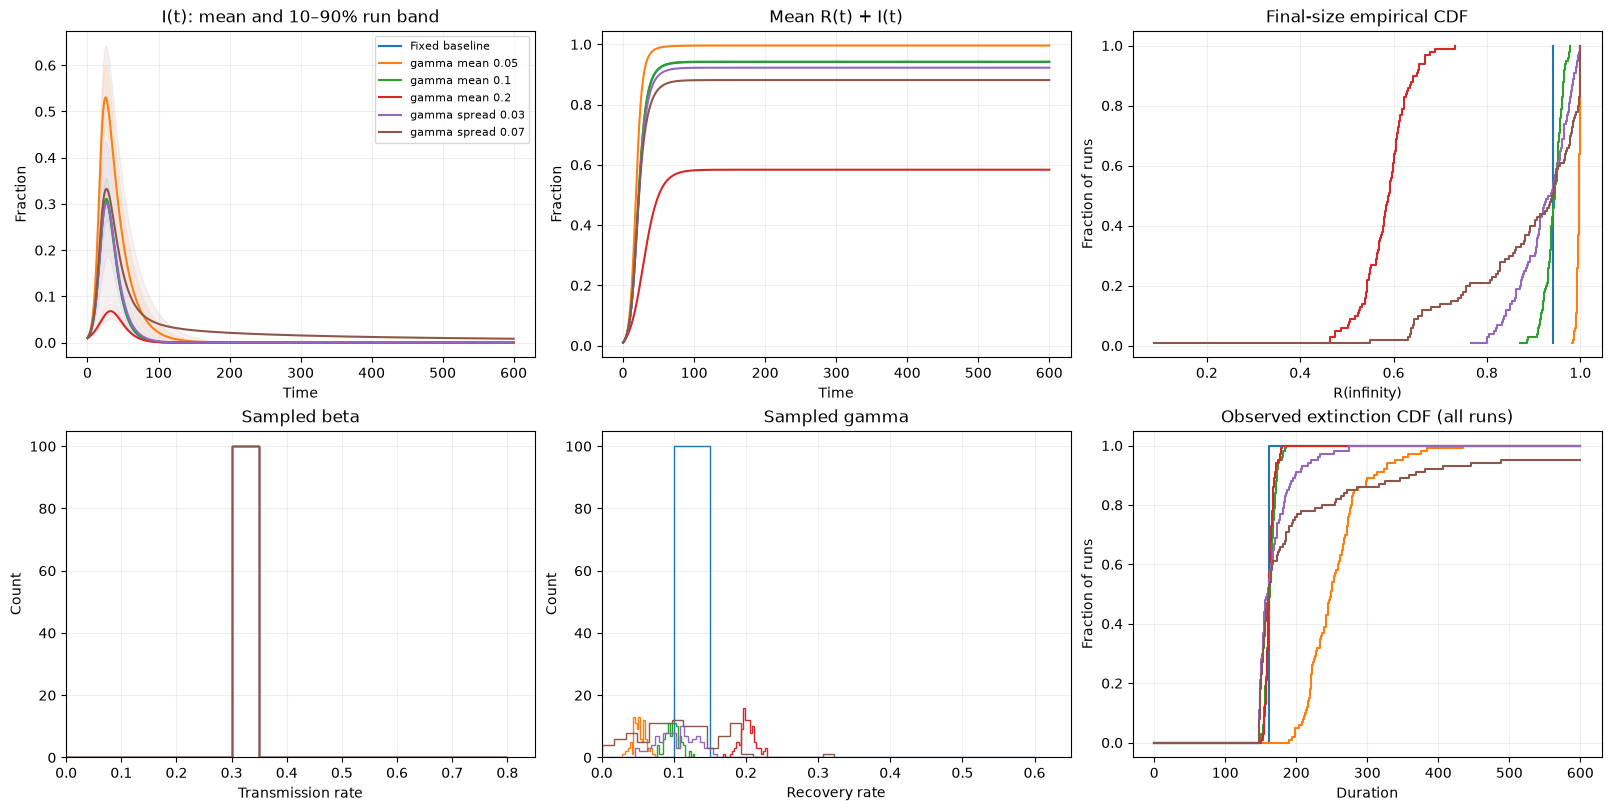

In [6]:
gamma_results = run_group(gamma_scenarios, SEED + 1)
summarize(gamma_results)
plot_group(gamma_results)

## 3. Independent Gaussian beta and gamma

Both parameters vary between runs. The epidemic initially grows if
`beta * (1 - I0) / gamma > 1`. The scatter plot below shows this threshold and
colors each sample by its infinite-time final size.

| Scenario | beta: sample mean ± SD | gamma: sample mean ± SD | R(infinity): mean ± SD | R(infinity): D1 / D5 / D9 | Duration censored | Mean duration, observed only |
| --- | --- | --- | --- | --- | --- | --- |
| Fixed baseline | 0.300 ± 0.000 | 0.100 ± 0.000 | 0.941 ± 0.000 | 0.941 / 0.941 / 0.941 | 0.0% | 161.3 |
| Both Gaussian: small | 0.300 ± 0.018 | 0.100 ± 0.011 | 0.939 ± 0.023 | 0.907 / 0.944 / 0.964 | 0.0% | 163.1 |
| Both Gaussian: medium | 0.306 ± 0.061 | 0.105 ± 0.032 | 0.895 ± 0.124 | 0.775 / 0.923 / 0.995 | 1.0% | 174.7 |
| Both Gaussian: large | 0.308 ± 0.124 | 0.116 ± 0.062 | 0.798 ± 0.262 | 0.402 / 0.895 / 0.999 | 4.0% | 198.5 |

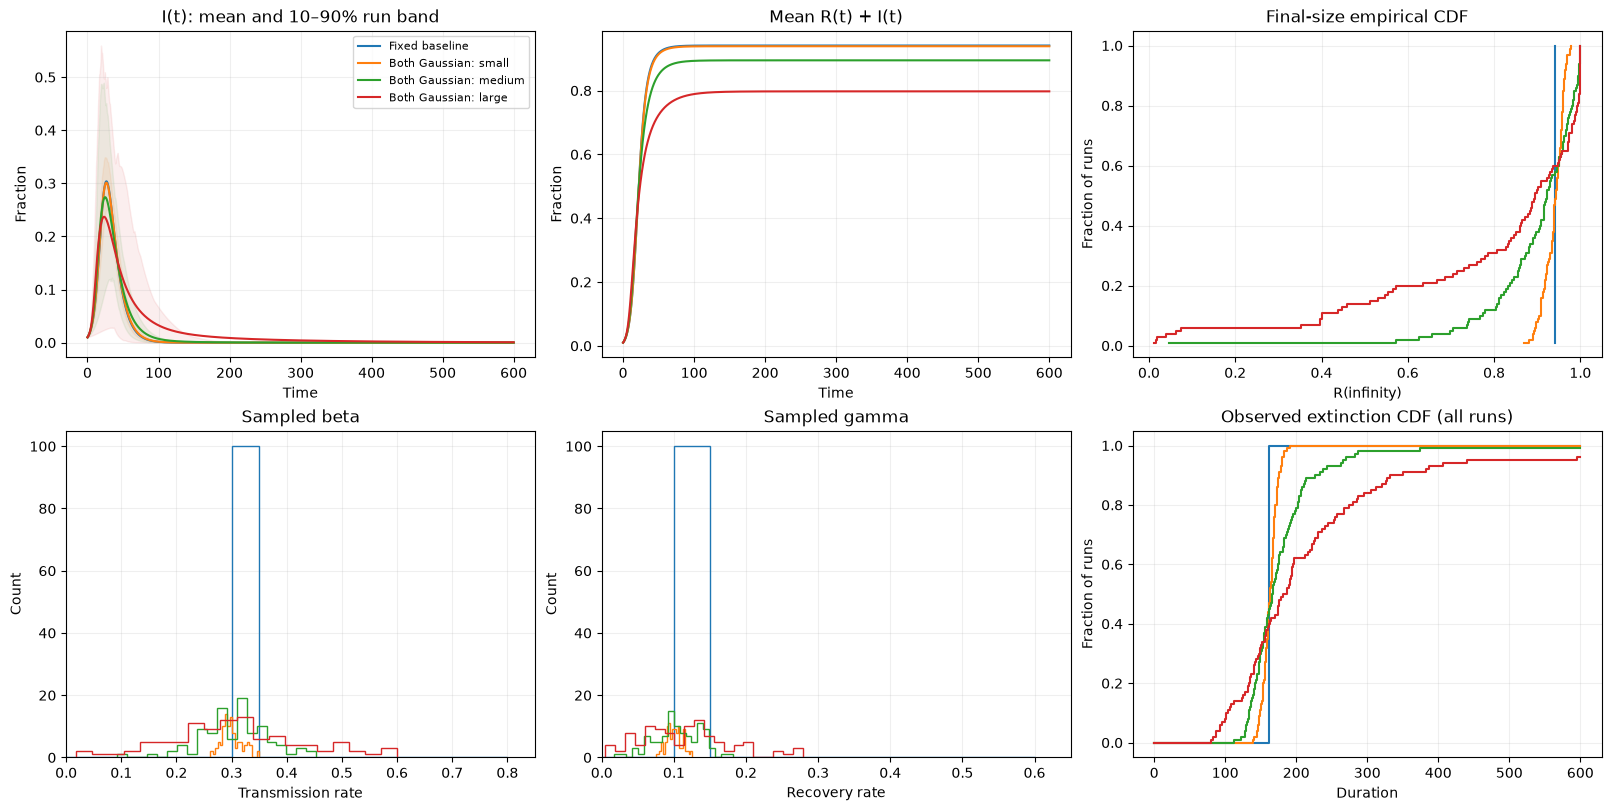

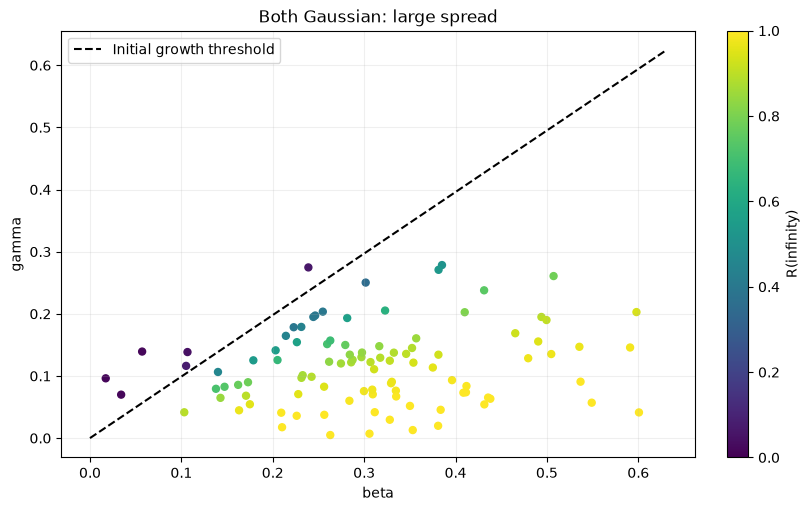

In [7]:
joint_results = run_group(joint_scenarios, SEED + 2)
summarize(joint_results)
plot_group(joint_results)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
result = joint_results[-1]
scatter = ax.scatter(result["beta"], result["gamma"], c=result["final_size"],
                     cmap="viridis", vmin=0, vmax=1, s=25)
x = np.linspace(0, result["beta"].max() * 1.05, 100)
ax.plot(x, x * (1 - I0), "k--", label="Initial growth threshold")
ax.set(xlabel="beta", ylabel="gamma", title="Both Gaussian: large spread")
ax.legend()
fig.colorbar(scatter, ax=ax, label="R(infinity)")
plt.show()

## 4. Gaussian versus uniform versus lognormal

Use the same nominal mean and SD for each rate. Uniform and lognormal parameters
are exact arithmetic moments. Gaussian parameters refer to the parent distribution,
so its conditional positive moments differ slightly. This comparison illustrates
distribution shape; it is not an exactly moment-matched truncated-normal comparison.

| Scenario | beta: sample mean ± SD | gamma: sample mean ± SD | R(infinity): mean ± SD | R(infinity): D1 / D5 / D9 | Duration censored | Mean duration, observed only |
| --- | --- | --- | --- | --- | --- | --- |
| Both gaussian | 0.296 ± 0.057 | 0.099 ± 0.031 | 0.911 ± 0.098 | 0.808 / 0.944 / 0.992 | 0.0% | 186.1 |
| Both uniform | 0.299 ± 0.059 | 0.103 ± 0.031 | 0.899 ± 0.104 | 0.734 / 0.936 / 0.993 | 0.0% | 180.4 |
| Both lognormal | 0.297 ± 0.058 | 0.101 ± 0.032 | 0.902 ± 0.110 | 0.769 / 0.945 / 0.996 | 0.0% | 180.5 |

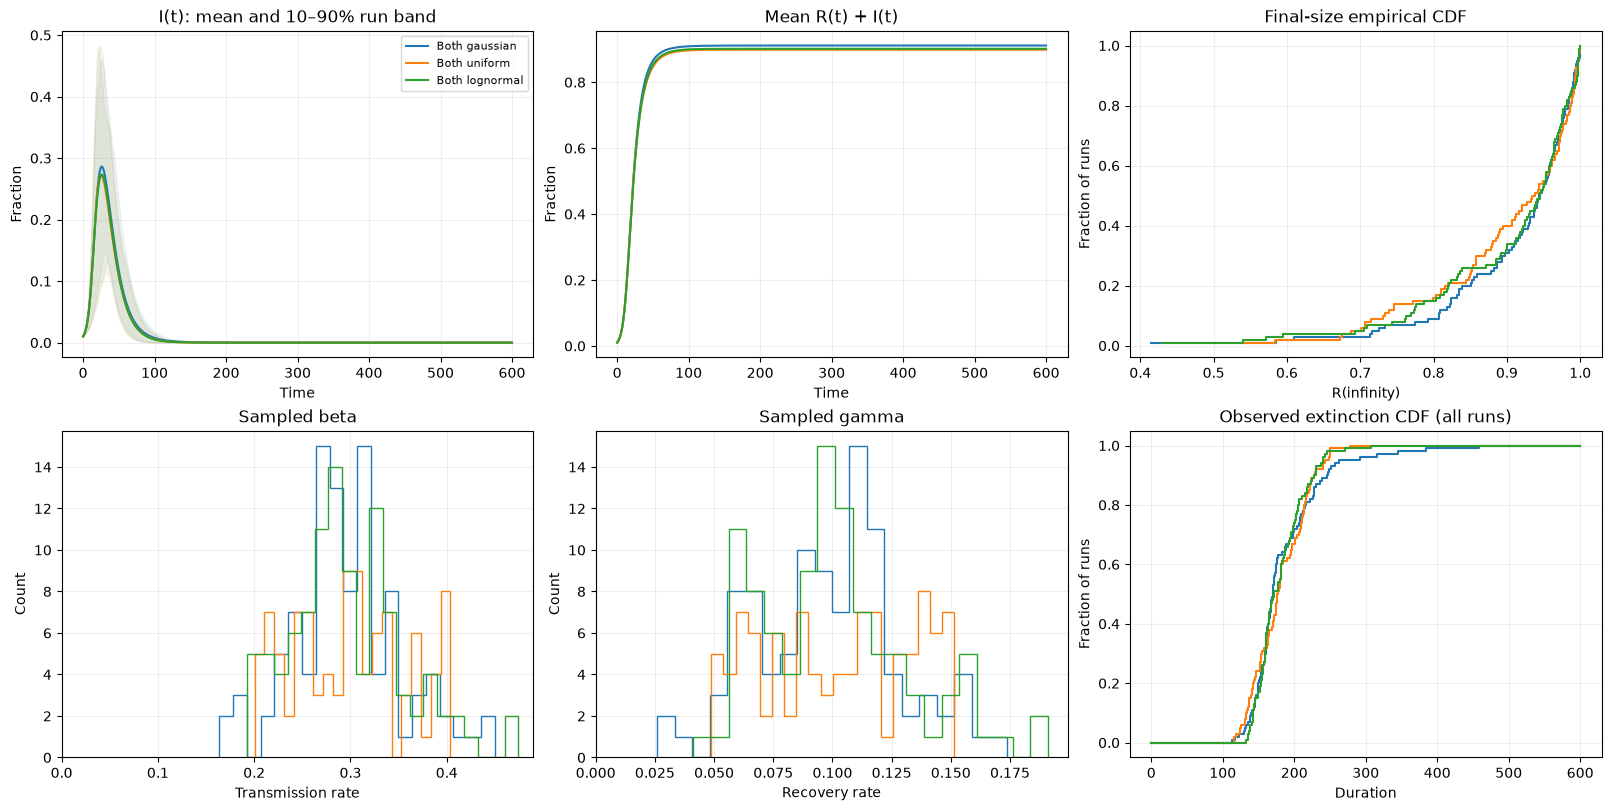

In [8]:
family_results = run_group(family_scenarios, SEED + 3)
summarize(family_results)
plot_group(family_results)

## 5. Individual paths and distributions at fixed times

Choose any completed scenario. Curves use the same time grid even when their
practical extinction times differ. After crossing the threshold, integration
continues normally; no trajectories are padded or manually set to zero.

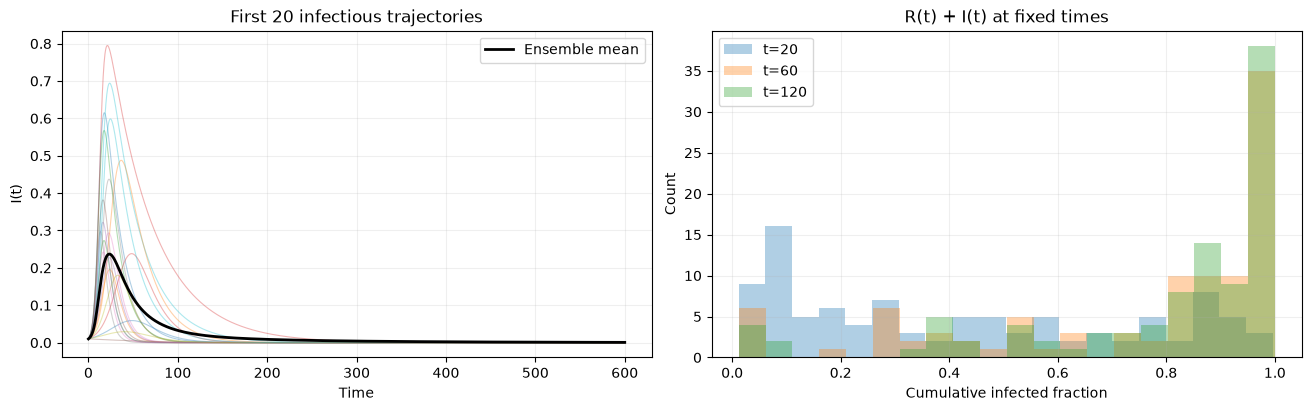

| Time | Mean R+I | SD | D1 / D5 / D9 |
| --- | --- | --- | --- |
| 20 | 0.4207 | 0.3139 | 0.0679 / 0.3528 / 0.8833 |
| 60 | 0.7503 | 0.2937 | 0.2983 / 0.8776 / 0.9983 |
| 120 | 0.7938 | 0.2643 | 0.3943 / 0.8921 / 0.9994 |

In [9]:
selected = joint_results[-1]  # Try beta_results[-1] or gamma_results[-1].
paths, times = selected["paths"], selected["times"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
for trajectory in paths[:20]:
    axes[0].plot(times, trajectory[1], alpha=0.35, linewidth=0.8)
axes[0].plot(times, paths[:, 1].mean(axis=0), "k", linewidth=2, label="Ensemble mean")
axes[0].set(title="First 20 infectious trajectories", xlabel="Time", ylabel="I(t)")
axes[0].legend()
rows = []
for time in OBSERVATION_TIMES:
    values = np.array([np.interp(time, times, path[1] + path[2]) for path in paths])
    axes[1].hist(values, bins=20, alpha=0.35, label=f"t={time:g}")
    rows.append([f"{time:g}", f"{values.mean():.4f}", f"{values.std(ddof=1):.4f}",
                 " / ".join(f"{q:.4f}" for q in np.quantile(values, [0.1, 0.5, 0.9]))])
axes[1].set(title="R(t) + I(t) at fixed times", xlabel="Cumulative infected fraction", ylabel="Count")
axes[1].legend()
plt.show()
markdown_table(["Time", "Mean R+I", "SD", "D1 / D5 / D9"], rows)

## 6. All deciles and duration censoring

The duration statistics below apply **only to observed threshold crossings**.
When censoring is present, these are not estimates of the full duration distribution.
Increase T_END and rerun the computation, or use survival-analysis methods to
study censoring explicitly. Final-size statistics include every run because the
analytical final-size equation does not depend on the observation horizon.

| Metric | Mean | Sample SD | D1 | D2 | D3 | D4 | D5 | D6 | D7 | D8 | D9 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| R(infinity), all runs | 0.7976 | 0.2620 | 0.4015 | 0.6234 | 0.7831 | 0.8617 | 0.8950 | 0.9415 | 0.9738 | 0.9933 | 0.9995 |
| Duration, observed only | 198.4855 | 88.5418 | 102.3992 | 133.0143 | 146.7533 | 159.7368 | 177.3370 | 194.0291 | 223.8411 | 257.1166 | 316.0057 |

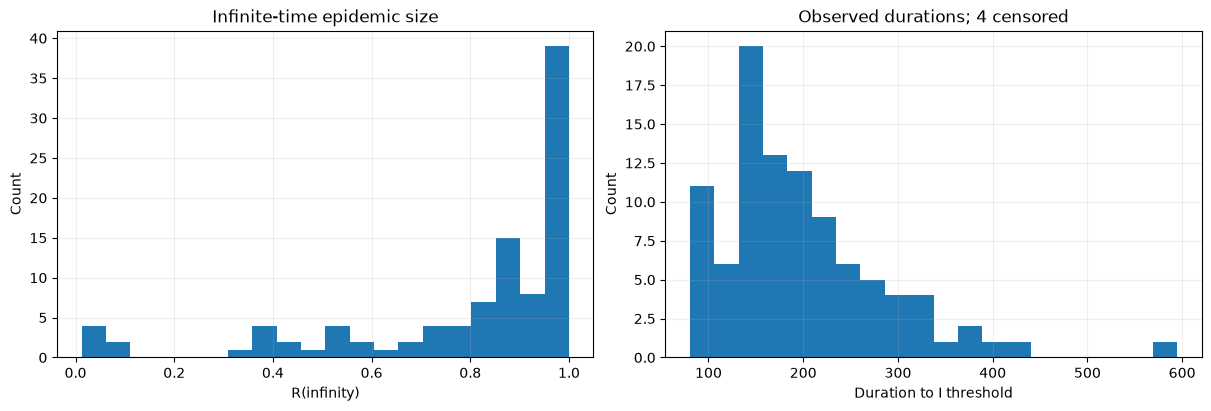

Scenario: Both Gaussian: large
beta distribution: gaussian: mu=0.3, sigma=0.12
gamma distribution: gaussian: mu=0.1, sigma=0.07
Observed durations: 96/100; censored: 4


In [10]:
probabilities = np.arange(0.1, 1.0, 0.1)
observed = selected["duration"][np.isfinite(selected["duration"])]
print("Scenario:", selected["config"]["name"])
print("beta distribution:", spec_text(selected["config"]["beta"]))
print("gamma distribution:", spec_text(selected["config"]["gamma"]))
print(f"Observed durations: {observed.size}/{N_RUNS}; censored: {N_RUNS - observed.size}")
rows = []
for label, values in (("R(infinity), all runs", selected["final_size"]),
                       ("Duration, observed only", observed)):
    if not values.size:
        continue
    sd = f"{values.std(ddof=1):.4f}" if values.size > 1 else "undefined (n=1)"
    rows.append([label, f"{values.mean():.4f}", sd]
                + [f"{q:.4f}" for q in np.quantile(values, probabilities)])
markdown_table(["Metric", "Mean", "Sample SD"] + [f"D{k}" for k in range(1, 10)], rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].hist(selected["final_size"], bins=20)
axes[0].set(title="Infinite-time epidemic size", xlabel="R(infinity)", ylabel="Count")
if observed.size:
    axes[1].hist(observed, bins=20)
axes[1].set(title=f"Observed durations; {N_RUNS - observed.size} censored",
            xlabel="Duration to I threshold", ylabel="Count")
plt.show()

## Interpretation and further experiments

1. Change `mu` while keeping `sigma` fixed to isolate the parent-mean effect.
2. Change `sigma` while keeping `mu` fixed to study parameter uncertainty.
3. Inspect empirical parameter moments when truncation is substantial.
4. Repeat with a different seed or larger N_RUNS to check Monte Carlo variability.
5. Increase T_END for censored runs and reduce OUTPUT_DT to refine duration estimates.
6. Compare the same scenarios at multiple I_THRESHOLD values: duration depends on
   this convention, while analytical R(infinity) does not.

A deterministic baseline repeated N_RUNS times has zero statistical spread.
Random parameters produce different deterministic trajectories; this experiment
does not model random individual contacts or time-varying environmental noise.

References: [SciPy solve_ivp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html),
[SciPy truncated normal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.truncnorm.html).